In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df=sns.load_dataset('tips')

In [30]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [6]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [8]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [13]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [20]:
for i in ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']:
    x=df[i].value_counts()
    print (x)

total_bill
13.42    3
13.81    2
15.98    2
17.92    2
10.07    2
        ..
24.71    1
21.16    1
28.97    1
22.49    1
18.78    1
Name: count, Length: 229, dtype: int64
tip
2.00    33
3.00    23
4.00    12
5.00    10
2.50    10
        ..
4.34     1
1.56     1
5.20     1
2.60     1
1.75     1
Name: count, Length: 123, dtype: int64
sex
Male      157
Female     87
Name: count, dtype: int64
smoker
No     151
Yes     93
Name: count, dtype: int64
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64
time
Dinner    176
Lunch      68
Name: count, dtype: int64
size
2    156
3     38
4     37
5      5
1      4
6      4
Name: count, dtype: int64


In [21]:
X=df[['tip', 'sex', 'smoker', 'day', 'time', 'size']]
y=df['total_bill']

In [24]:
type(X)

pandas.core.frame.DataFrame

In [25]:
type(y)

pandas.core.series.Series

In [28]:
from sklearn.model_selection import train_test_split as tts

In [55]:
X_train,X_test,y_train,y_test=tts(X,y,random_state=42,test_size=0.25)

In [56]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((183, 6), (61, 6), (183,), (61,))

In [57]:
from sklearn.preprocessing import LabelEncoder

In [58]:
le1=LabelEncoder()
le2=LabelEncoder()
le3=LabelEncoder()

In [59]:
X_train.head()

,tip,sex,smoker,day,time,size
115,3.50,Female,No,Sun,Dinner,2
181,5.65,Male,Yes,Sun,Dinner,2
225,2.50,Female,Yes,Fri,Lunch,2
68,2.01,Male,No,Sat,Dinner,2
104,4.08,Female,No,Sat,Dinner,2


In [60]:
import warnings
warnings.filterwarnings('ignore')
X_train['sex']=le1.fit_transform(X_train['sex'])
X_train['smoker']=le2.fit_transform(X_train['smoker'])
X_train['time']=le3.fit_transform(X_train['time'])

In [61]:
X_train.head()

,tip,sex,smoker,day,time,size
115,3.50,0,0,Sun,0,2
181,5.65,1,1,Sun,0,2
225,2.50,0,1,Fri,1,2
68,2.01,1,0,Sat,0,2
104,4.08,0,0,Sat,0,2


In [62]:
X_train['time'].value_counts()

time
0    132
1     51
Name: count, dtype: int64

In [63]:
X_test['sex']=le1.fit_transform(X_test['sex'])
X_test['smoker']=le2.fit_transform(X_test['smoker'])
X_test['time']=le3.fit_transform(X_test['time'])

In [64]:
X_test.head()

,tip,sex,smoker,day,time,size
24,3.18,1,0,Sat,0,2
6,2.00,1,0,Sun,0,2
153,2.00,1,0,Sun,0,4
211,5.16,1,1,Sat,0,4
198,2.00,0,1,Thur,1,2


In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [66]:
ct=ColumnTransformer(transformers=[('onehot',OneHotEncoder(drop='first'),[3])],
                                   remainder='passthrough')

In [67]:
X_train=ct.fit_transform(X_train)
X_test=ct.transform(X_test)

In [68]:
X_train

array([[ 0.  ,  1.  ,  0.  ,  3.5 ,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 0.  ,  1.  ,  0.  ,  5.65,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 0.  ,  0.  ,  0.  ,  2.5 ,  0.  ,  1.  ,  1.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  2.01,  1.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  4.08,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  2.09,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  1.  ,  0.  ,  0.  ,  0.  ,  1.  ],
       [ 1.  ,  0.  ,  0.  ,  3.41,  1.  ,  1.  ,  0.  ,  3.  ],
       [ 0.  ,  1.  ,  0.  ,  3.48,  1.  ,  0.  ,  0.  ,  3.  ],
       [ 0.  ,  1.  ,  0.  ,  2.  ,  1.  ,  0.  ,  0.  ,  4.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  1.  ,  1.  ,  0.  ,  5.  ],
       [ 0.  ,  0.  ,  1.  ,  2.71,  1.  ,  0.  ,  1.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  1.  ,  0.  ,  0.  ,  4.  ],
       [ 0.  ,  1.  ,  0.

In [69]:
X_test

array([[1.  , 0.  , 0.  , 3.18, 1.  , 0.  , 0.  , 2.  ],
       [0.  , 1.  , 0.  , 2.  , 1.  , 0.  , 0.  , 2.  ],
       [0.  , 1.  , 0.  , 2.  , 1.  , 0.  , 0.  , 4.  ],
       [1.  , 0.  , 0.  , 5.16, 1.  , 1.  , 0.  , 4.  ],
       [0.  , 0.  , 1.  , 2.  , 0.  , 1.  , 1.  , 2.  ],
       [0.  , 1.  , 0.  , 2.  , 1.  , 1.  , 0.  , 2.  ],
       [0.  , 0.  , 1.  , 2.56, 1.  , 1.  , 1.  , 2.  ],
       [0.  , 0.  , 1.  , 2.52, 0.  , 0.  , 1.  , 2.  ],
       [0.  , 1.  , 0.  , 3.23, 1.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 0.  , 3.  , 0.  , 1.  , 0.  , 2.  ],
       [0.  , 1.  , 0.  , 3.  , 1.  , 0.  , 0.  , 2.  ],
       [1.  , 0.  , 0.  , 1.47, 1.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 1.  , 1.5 , 0.  , 0.  , 1.  , 2.  ],
       [0.  , 1.  , 0.  , 2.  , 1.  , 1.  , 0.  , 2.  ],
       [0.  , 0.  , 1.  , 1.83, 0.  , 0.  , 1.  , 1.  ],
       [0.  , 0.  , 1.  , 1.36, 0.  , 0.  , 1.  , 3.  ],
       [0.  , 0.  , 1.  , 4.  , 1.  , 1.  , 1.  , 3.  ],
       [0.  , 1.  , 0.  , 3.92,

In [70]:
import sys
np.set_printoptions(threshold=sys.maxsize)

In [71]:
X_train

array([[ 0.  ,  1.  ,  0.  ,  3.5 ,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 0.  ,  1.  ,  0.  ,  5.65,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 0.  ,  0.  ,  0.  ,  2.5 ,  0.  ,  1.  ,  1.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  2.01,  1.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  4.08,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  2.09,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  1.  ,  0.  ,  0.  ,  0.  ,  1.  ],
       [ 1.  ,  0.  ,  0.  ,  3.41,  1.  ,  1.  ,  0.  ,  3.  ],
       [ 0.  ,  1.  ,  0.  ,  3.48,  1.  ,  0.  ,  0.  ,  3.  ],
       [ 0.  ,  1.  ,  0.  ,  2.  ,  1.  ,  0.  ,  0.  ,  4.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  1.  ,  1.  ,  0.  ,  5.  ],
       [ 0.  ,  0.  ,  1.  ,  2.71,  1.  ,  0.  ,  1.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  0.  ,  0.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  1.  ,  1.  ,  0.  ,  2.  ],
       [ 1.  ,  0.  ,  0.  ,  3.  ,  1.  ,  0.  ,  0.  ,  4.  ],
       [ 0.  ,  1.  ,  0.

In [72]:
from sklearn.svm import SVR
svr=SVR()
svr.fit(X_train,y_train)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [73]:
y_pred=svr.predict(X_test)
y_pred

array([17.5561784 , 14.36577654, 19.63397234, 28.25543047, 14.02663803,
       15.14661512, 15.65622876, 14.69846537, 17.74841731, 17.10279588,
       17.00871008, 13.11497368, 12.69657312, 15.14661512, 12.61920692,
       14.56276428, 22.36183592, 20.05495874, 15.19753962, 27.62501035,
       20.51137651, 20.70196982, 20.81712863, 13.09052072, 21.43691299,
       14.41684672, 13.85511311, 23.80397724, 19.63397234, 27.64931837,
       22.79293822, 13.8188067 , 20.30086231, 18.25263814, 20.98187239,
       21.0145318 , 13.75259705, 26.55345115, 15.35776158, 14.77444494,
       12.88789193, 13.46643546, 15.6772362 , 15.81001   , 14.37448237,
       12.8355147 , 13.91918958, 17.21837273, 12.89649108, 15.99658633,
       14.83989577, 20.674379  , 26.42594064, 13.792125  , 18.67892859,
       13.73233647, 23.77247816, 13.53584868, 18.67078969, 20.11314707,
       28.25510507])

In [74]:
from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))

0.49798620106004743
4.463296539661225


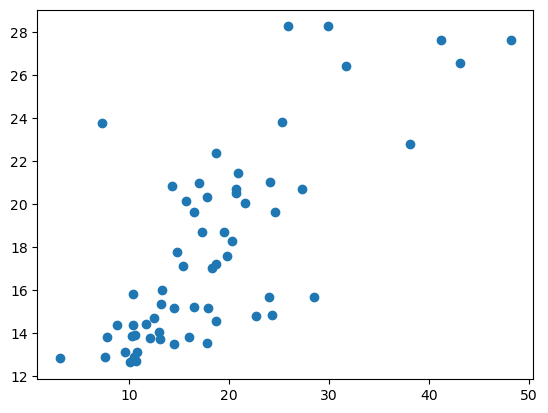

In [75]:
plt.scatter(y_test,y_pred)

In [76]:
from sklearn.model_selection import GridSearchCV
 
# defining parameter range
param_grid = {'C': [0.1, 1, 10, 100, 1000],
              'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
              'kernel': ['rbf']}

In [77]:
svr=SVR()
grid = GridSearchCV(svr, param_grid, refit = True, verbose = 3)
 
# fitting the model for grid search
grid.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.114 total time=   0.0s
[CV 2/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.008 total time=   0.0s
[CV 3/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.003 total time=   0.0s
[CV 4/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.015 total time=   0.0s
[CV 5/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.123 total time=   0.0s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.019 total time=   0.0s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.096 total time=   0.0s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.078 total time=   0.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.099 total time=   0.0s
[CV 5/5] END .....C=0.1, gamma=0.1, kernel=rbf;, score=-0.020 total time=   0.0s
[CV 1/5] END ....C=0.1, gamma=0.01, kernel=rbf;, score=-0.102 total time=   0.0s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

,estimator,SVR()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...], 'kernel': ['rbf']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,kernel,'rbf'


In [78]:
grid_prediction=grid.predict(X_test)

In [79]:
print(r2_score(y_test,grid_prediction))
print(mean_absolute_error(y_test,grid_prediction))

0.5630727637616455
4.260483973872266
